In [1]:

from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/1e275a2206db45a08b19f2545e2ae8f5:46562652-ebad-4e2b-a27a-1531217eb801::"
)

import pandas as pd
import numpy as np

TARGET = "01100"

JOBS = {
    "None": "dbm9mld8ft8s738uf8i0",
    "XpXm": "dbm9lvu74qds73drssp0",
    "XX": "dbm9val8mdtc73d7iuvg",
    "XY4": "dbma03u74qds73drticg",
    "Twirling": "dbm9mud8mdtc73d7iclg",
    "XpXm + Twirling": "dbm9kpu74qds73drsr20",
    "XX + Twirling": "dbm9uju74qds73drteug",
    "XY4 + Twirling": "dbma14m74qds73drtkng",
}

# Generate all 32 possible basis states
ALL_STATES = [format(i, "05b") for i in range(32)]

OTHER_STATES = [s for s in ALL_STATES if s != TARGET]

summary = []
distributions = []

for experiment, job_id in JOBS.items():

    print(f"Processing {experiment}...")

    job = service.job(job_id)

    if str(job.status()) not in ["DONE", "JobStatus.DONE"]:
        print("Skipping:", job.status())
        continue

    result = job.result()

    for pub_index, pub in enumerate(result):

        counts = pub.data.meas.get_counts()
        shots = sum(counts.values())

        # Target state
        target_counts = counts.get(TARGET, 0)
        target_probability = target_counts / shots

        # Average probability of the other 31 states
        other_probabilities = [
            counts.get(state, 0) / shots
            for state in OTHER_STATES
        ]

        other_average = np.mean(other_probabilities)

        # Standard error of target probability
        stderr = np.sqrt(
            target_probability * (1 - target_probability) / shots
        )

        summary.append({
            "Experiment": experiment,
            "Job ID": job_id,
            "PUB": pub_index,
            "Shots": shots,
            "Target Counts": target_counts,
            "Target (%)": target_probability * 100,
            "Other States Average (%)": other_average * 100,
            "Target / Other Average":
                target_probability / other_average
                if other_average > 0 else np.nan,
            "Standard Error (%)": stderr * 100,
        })

        # Save complete probability distribution
        for state in ALL_STATES:

            state_counts = counts.get(state, 0)

            distributions.append({
                "Experiment": experiment,
                "State": state,
                "Counts": state_counts,
                "Probability (%)": state_counts / shots * 100
            })

summary_df = pd.DataFrame(summary)
distribution_df = pd.DataFrame(distributions)

print("\n===== RESULTS =====")
print(summary_df.to_string(index=False))

# Export results
summary_df.to_csv("grover_summary.csv", index=False)
distribution_df.to_csv("grover_distributions.csv", index=False)

print("\nSaved:")
print("grover_summary.csv")
print("grover_distributions.csv")


Processing None...
Processing XpXm...
Processing XX...
Processing XY4...
Processing Twirling...
Processing XpXm + Twirling...
Processing XX + Twirling...
Processing XY4 + Twirling...

===== RESULTS =====
     Experiment               Job ID  PUB  Shots  Target Counts  Target (%)  Other States Average (%)  Target / Other Average  Standard Error (%)
           None dbm9mld8ft8s738uf8i0    0   4096            617   15.063477                  2.739888                5.497844            0.558895
           XpXm dbm9lvu74qds73drssp0    0   4096            633   15.454102                  2.727287                5.666474            0.564792
             XX dbm9val8mdtc73d7iuvg    0   4096            140    3.417969                  3.115549                1.097068            0.283891
            XY4 dbma03u74qds73drticg    0   4096            137    3.344727                  3.117912                1.072746            0.280940
       Twirling dbm9mud8mdtc73d7iclg    0   4096            480   

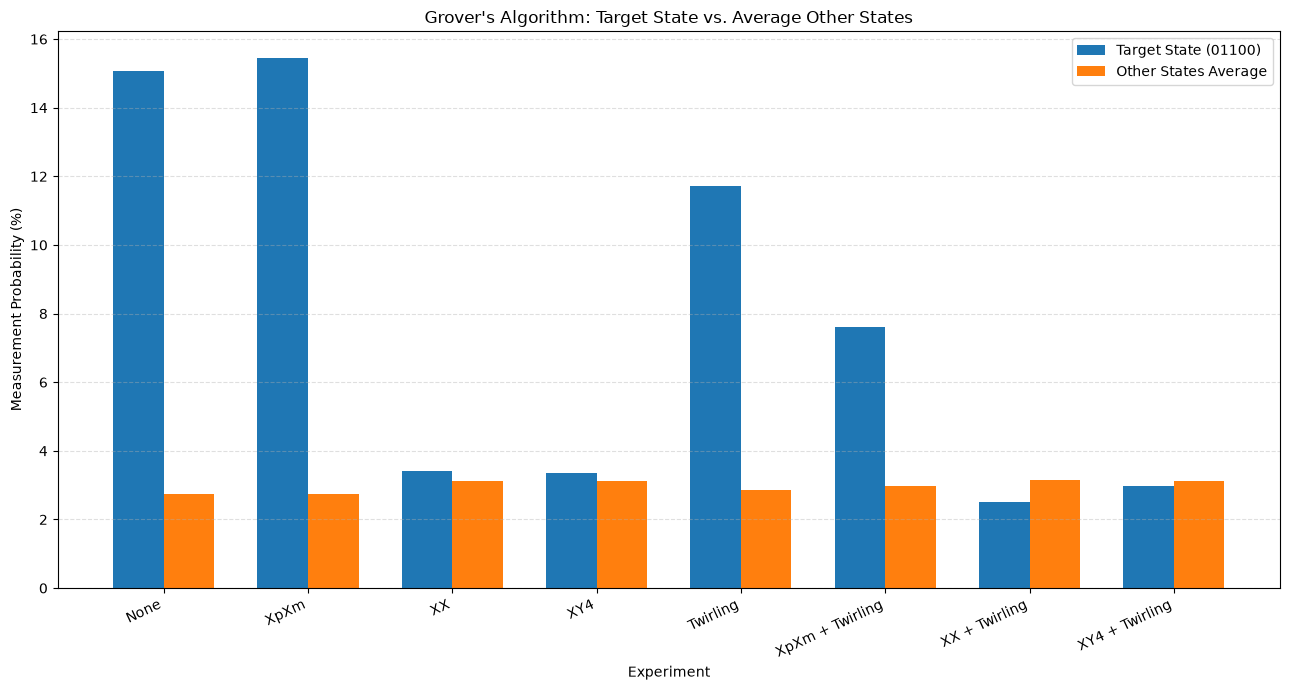

Saved: grover_comparison.png


In [2]:

import matplotlib.pyplot as plt

# ===== GRAPH: TARGET VS OTHER STATES AVERAGE =====

plot_df = summary_df.groupby("Experiment", sort=False).agg({
    "Target (%)": "mean",
    "Other States Average (%)": "mean"
}).reset_index()

x = np.arange(len(plot_df))
width = 0.35

plt.figure(figsize=(13, 7))

plt.bar(
    x - width / 2,
    plot_df["Target (%)"],
    width,
    label="Target State (01100)"
)

plt.bar(
    x + width / 2,
    plot_df["Other States Average (%)"],
    width,
    label="Other States Average"
)

plt.xticks(x, plot_df["Experiment"], rotation=25, ha="right")

plt.ylabel("Measurement Probability (%)")
plt.xlabel("Experiment")
plt.title("Grover's Algorithm: Target State vs. Average Other States")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("grover_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: grover_comparison.png")
